<a href="https://colab.research.google.com/github/uniqueeee777/stability-aware-multiview-food-security/blob/main/05_Stability_Assessment_R0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Persiapan dan identitas eksperimen

In [ ]:

# ============================================================
# CELL 1 — FULL STABILITY ASSESSMENT SETUP
# ============================================================

!pip -q install "kmedoids==0.5.5"

from google.colab import drive
from pathlib import Path
from importlib.metadata import version
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import SpectralClustering
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, cut_tree
from scipy.sparse.csgraph import connected_components
from IPython.display import display

import numpy as np
import pandas as pd
import scipy
import sklearn
import kmedoids
import hashlib
import json
import os

drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

GRID_DIR = (
    ROOT / "03_outputs" / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
)

SOURCE = (
    ROOT / "01_data" / "01_raw"
    / "MATRIX_9VAR_CLUSTERING_85KAB_2025.csv"
)

EXPECTED_HASH = (
    "ce932d322eb49cbdb6ea3b0a8768ca89c2e9"
    "e7f0722232883541d891089ca6fa"
)

assert SOURCE.exists()
assert hashlib.sha256(
    SOURCE.read_bytes()
).hexdigest() == EXPECTED_HASH

df = pd.read_csv(
    SOURCE, dtype={"kode_bps": "string"}
)

grid = pd.read_csv(
    GRID_DIR / "quality_grid_all.csv"
)

labels_full = pd.read_csv(
    GRID_DIR / "labels_all.csv",
    dtype={"kode_bps": "string"}
)

assert len(df) == 85
assert len(grid) == 395
assert len(labels_full) == 85
assert grid["model_id"].is_unique
assert set(grid["model_id"]) == (
    set(labels_full.columns) - {"kode_bps"}
)
assert np.array_equal(
    df["kode_bps"].astype(str).to_numpy(),
    labels_full["kode_bps"].astype(str).to_numpy()
)

VIEWS = {
    "Food": [
        "F1_ikp_ketersediaan",
        "F2_ikp_keterjangkauan",
        "F3_ikp_pemanfaatan"
    ],
    "Climate": [
        "C1_anomali_hujan_mm",
        "C2_cdd_hari",
        "C3_hari_hujan_ekstrem"
    ],
    "Accessibility": [
        "A1_persen_tanpa_angkutan",
        "A2_persen_jalan_tanah_lainnya",
        "A3_persen_tanpa_pertokoan_pasar"
    ]
}

FEATURES = sum(VIEWS.values(), [])

WEIGHTS = {
    "equal": (1/3, 1/3, 1/3),
    "food50": (0.5, 0.25, 0.25),
    "climate50": (0.25, 0.5, 0.25),
    "access50": (0.25, 0.25, 0.5)
}

VIEW_ORDER = list(VIEWS.keys())

SEED = 20261019
B_SELECTION = 100
BATCH_SIZE = 5

# Stable output folder enables checkpoint/resume.
RUN_NAME = "R0_all395_selection_v1"

OUT = (
    ROOT / "03_outputs" / "06_stability_selection"
    / RUN_NAME
)

OUT.mkdir(parents=True, exist_ok=True)

# File hashes for provenance
def sha256(path):
    return hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

manifest = {
    "protocol": "R0-stability-selection-v1",
    "input_sha256": EXPECTED_HASH,
    "grid_sha256": sha256(
        GRID_DIR / "quality_grid_all.csv"
    ),
    "labels_sha256": sha256(
        GRID_DIR / "labels_all.csv"
    ),
    "n_candidates": 395,
    "n_subsamples": B_SELECTION,
    "fraction": 0.8,
    "stratification": "provinsi",
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "scikit_learn": sklearn.__version__,
    "scipy": scipy.__version__,
    "numpy": np.__version__,
    "kmedoids": version("kmedoids"),
    "status": "SELECTION_ASSESSMENT_ONLY"
}

manifest_path = OUT / "manifest.json"

if manifest_path.exists():
    old_manifest = json.loads(
        manifest_path.read_text()
    )

    if old_manifest != manifest:
        raise ValueError(
            "Protocol/environment mismatch. "
            "Use a new RUN_NAME; do not mix runs."
        )
else:
    manifest_path.write_text(
        json.dumps(manifest, indent=2),
        encoding="utf-8"
    )

# Pre-generate the same subsets for all candidates
splitter = StratifiedShuffleSplit(
    n_splits=B_SELECTION,
    train_size=0.8,
    random_state=SEED
)

SUBSETS = [
    train_idx
    for train_idx, _ in splitter.split(
        df, df["provinsi"]
    )
]

assert len(SUBSETS) == 100
assert all(len(s) == 68 for s in SUBSETS)

print("STABILITY PROTOCOL VERIFIED")
print("Candidates:", len(grid))
print("Subsamples:", len(SUBSETS))
print("Output:", OUT)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 457.4/457.4 kB 1.8 MB/s eta 0:00:00
Mounted at /content/drive
STABILITY PROTOCOL VERIFIED
Candidates: 395
Subsamples: 100
Output: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/06_stability_selection/R0_all395_selection_v1


# Fungsi refitting dan evaluasi stabilitas

In [ ]:

# ============================================================
# CELL 2 — STABILITY REFITTING FUNCTIONS
# ============================================================

def prepare_subset(indices):
    Y = df.iloc[indices][FEATURES].astype(float)

    sd = Y.std(ddof=1)

    if (sd <= 0).any() or sd.isna().any():
        raise ValueError("Invalid subset standard deviation.")

    Z = (Y - Y.mean()) / sd

    blocks = []
    distances = {}

    for view, cols in VIEWS.items():
        A = Z[cols].to_numpy(dtype=float)

        D = squareform(pdist(A)) / np.sqrt(len(cols))
        upper = D[np.triu_indices(len(D), 1)]
        rms = np.sqrt(np.mean(upper ** 2))

        if rms <= 0 or not np.isfinite(rms):
            raise ValueError("Invalid view RMS.")

        factor = np.sqrt(2) / rms
        distances[view] = D * factor

        blocks.append(
            A * factor * np.sqrt(1 / (3 * len(cols)))
        )

    Phi = np.column_stack(blocks)
    D_fused = squareform(pdist(Phi))

    assert np.allclose(
        D_fused,
        np.sqrt(sum(d ** 2 / 3 for d in distances.values()))
    )

    return Phi, D_fused, distances


def make_graph(D, kg, ks):
    n = D.shape[0]

    if not (1 <= kg < n and 1 <= ks < n):
        raise ValueError("Invalid graph parameters.")

    if not np.allclose(D, D.T) or not np.isfinite(D).all():
        raise ValueError("Invalid distance matrix.")

    A = D.copy()
    np.fill_diagonal(A, np.inf)

    order = np.argsort(A, axis=1, kind="stable")
    sigma = A[np.arange(n), order[:, ks - 1]]

    if (sigma <= 0).any() or not np.isfinite(sigma).all():
        raise ValueError("Invalid local bandwidth.")

    adjacency = np.zeros((n, n), dtype=bool)
    adjacency[np.arange(n)[:, None], order[:, :kg]] = True
    adjacency |= adjacency.T

    W = np.exp(
        -(D ** 2) /
        (sigma[:, None] * sigma[None, :])
    )

    W = np.where(adjacency, W, 0.0)
    np.fill_diagonal(W, 0.0)

    components = connected_components(
        (W > 0).astype(np.uint8),
        directed=False
    )[0]

    if components != 1:
        raise ValueError(
            f"Disconnected graph: {components} components."
        )

    return W


def make_fit_context(indices):
    """
    Calculate preprocessing, hierarchical trees,
    and caches only once for each subsampling repeat.
    """

    Phi, D, D_views = prepare_subset(indices)

    trees = {
        "Hierarchical_Ward": linkage(
            Phi, method="ward", metric="euclidean"
        ),
        "Hierarchical_Average": linkage(
            squareform(D, checks=True),
            method="average"
        ),
        "Hierarchical_Complete": linkage(
            squareform(D, checks=True),
            method="complete"
        )
    }

    return {
        "Phi": Phi,
        "D": D,
        "D_views": D_views,
        "trees": trees,
        "graph_cache": {}
    }


def get_graph(ctx, method, kg, ks, weight_id):
    cache = ctx["graph_cache"]
    key = (method, kg, ks, weight_id)

    if key in cache:
        return cache[key]

    if method == "Spectral_Early":
        W = make_graph(ctx["D"], kg, ks)

    elif method == "Spectral_MultiView":
        weights = WEIGHTS[weight_id]

        W = np.zeros_like(ctx["D"])

        for i, view in enumerate(VIEW_ORDER):
            Wv = make_graph(ctx["D_views"][view], kg, ks)
            norm = np.linalg.norm(Wv, "fro")

            if norm <= 0 or not np.isfinite(norm):
                raise ValueError("Invalid graph norm.")

            W += weights[i] * Wv / norm

    else:
        raise ValueError("Unknown spectral method.")

    cache[key] = W
    return W


def fit_model(row, ctx):
    method = row["method"]
    K = int(row["K"])

    if method == "KMedoids_PAM":
        labels = kmedoids.pam(
            ctx["D"], K,
            init="build",
            max_iter=300,
            random_state=SEED
        ).labels

    elif method in ctx["trees"]:
        labels = cut_tree(
            ctx["trees"][method],
            n_clusters=K
        ).ravel()

    elif method.startswith("Spectral_"):
        W = get_graph(
            ctx, method,
            int(row["k_graph"]),
            int(row["k_scale"]),
            row["weight_id"]
        )

        model = SpectralClustering(
            n_clusters=K,
            affinity="precomputed",
            assign_labels="kmeans",
            eigen_solver="arpack",
            n_init=20,
            random_state=SEED
        )
        labels = model.fit_predict(W)

    else:
        raise ValueError(f"Unknown method: {method}")

    labels = np.asarray(labels, dtype=int)

    if len(np.unique(labels)) != K:
        raise ValueError("Incorrect number of clusters.")

    return labels


def assess_partition(reference, fitted):
    """
    ARI and cluster-wise Jaccard on the same subset.

    A missing reference cluster has NA Jaccard,
    and its absence is separately recorded.
    """
    ari = adjusted_rand_score(reference, fitted)

    cluster_results = []

    for c in np.unique(reference):
        a = reference == c

        best = max(
            np.sum(a & (fitted == d))
            / np.sum(a | (fitted == d))
            for d in np.unique(fitted)
        )

        cluster_results.append((int(c), float(best), int(a.sum())))

    return float(ari), cluster_results


# Full-data geometry reproduction check
ctx_full = make_fit_context(np.arange(85))

with np.load(
    ROOT / "03_outputs" / "02_representation"
    / "20261018_173812_UTC"
    / "R0_raw_zscore_distances.npz",
    allow_pickle=False
) as f:
    D_check = f["fused"]

assert np.allclose(ctx_full["D"], D_check, atol=1e-10)

print("REFITTING FUNCTIONS VERIFIED")
print("Full-data representation reproduced.")


REFITTING FUNCTIONS VERIFIED
Full-data representation reproduced.


# 2A — Koreksi seed, pemeriksaan seluruh partisi, dan protokol eksperimen V2

In [ ]:

# ============================================================
# CELL 2A — SEED-ALIGNED STABILITY PROTOCOL V2
#
# Reference model seed : 20261018
# Subsampling seed     : 20261019
#
# Reuses existing functions from Notebook 05 Cell 2.
# Creates a NEW output directory.
# Never overwrites V1 results.
# ============================================================

from pathlib import Path
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import adjusted_rand_score
from importlib.metadata import version
from IPython.display import display

import numpy as np
import pandas as pd
import sklearn
import scipy
import hashlib
import json

# ------------------------------------------------------------
# 1. READ ORIGINAL EXPERIMENT PROTOCOLS
# ------------------------------------------------------------

GRID_PROTOCOL_PATH = GRID_DIR / "protocol.json"

V1_DIR = (
    ROOT / "03_outputs"
    / "06_stability_selection"
    / "R0_all395_selection_v1"
)

V1_MANIFEST_PATH = V1_DIR / "manifest.json"

assert GRID_PROTOCOL_PATH.exists()
assert V1_MANIFEST_PATH.exists()

grid_protocol = json.loads(
    GRID_PROTOCOL_PATH.read_text(
        encoding="utf-8"
    )
)

v1_manifest = json.loads(
    V1_MANIFEST_PATH.read_text(
        encoding="utf-8"
    )
)

MODEL_SEED = int(
    grid_protocol["random_seed"]
)

SUBSAMPLE_SEED = int(
    v1_manifest["seed"]
)

assert MODEL_SEED == 20261018
assert SUBSAMPLE_SEED == 20261019
assert MODEL_SEED != SUBSAMPLE_SEED

# ------------------------------------------------------------
# 2. VERIFY INPUT FILES AND SOFTWARE ENVIRONMENT
# ------------------------------------------------------------

def file_hash(path):
    return hashlib.sha256(
        Path(path).read_bytes()
    ).hexdigest()


assert file_hash(SOURCE) == EXPECTED_HASH

assert file_hash(
    GRID_DIR / "quality_grid_all.csv"
) == v1_manifest["grid_sha256"]

assert file_hash(
    GRID_DIR / "labels_all.csv"
) == v1_manifest["labels_sha256"]

assert sklearn.__version__ == v1_manifest["scikit_learn"]
assert scipy.__version__ == v1_manifest["scipy"]
assert np.__version__ == v1_manifest["numpy"]
assert version("kmedoids") == v1_manifest["kmedoids"]

assert len(grid) == 395
assert len(df) == 85
assert grid["model_id"].is_unique

# ------------------------------------------------------------
# 3. RECONSTRUCT EXACTLY THE ORIGINAL 100 SUBSETS
# ------------------------------------------------------------

B_SELECTION = 100
BATCH_SIZE = 5

splitter_v2 = StratifiedShuffleSplit(
    n_splits=B_SELECTION,
    train_size=0.8,
    random_state=SUBSAMPLE_SEED
)

SUBSETS = [
    train_idx.copy()
    for train_idx, _ in splitter_v2.split(
        df,
        df["provinsi"]
    )
]

assert len(SUBSETS) == B_SELECTION
assert all(len(idx) == 68 for idx in SUBSETS)

# Use MODEL_SEED in the previously defined fit_model().
# The old function reads the global variable SEED.
SEED = MODEL_SEED

print("SEED CONFIGURATION")
print("Model fitting seed:", SEED)
print("Subsampling seed :", SUBSAMPLE_SEED)
print("Subsample count  :", len(SUBSETS))

# ------------------------------------------------------------
# 4. FULL-DATA REPRODUCTION TEST: ALL 395 MODELS
# ------------------------------------------------------------

ctx_full_v2 = make_fit_context(
    np.arange(len(df))
)

audit_rows = []

for model in grid.to_dict("records"):

    model_id = model["model_id"]

    ref_labels = labels_full[
        model_id
    ].to_numpy(dtype=int)

    fitted_labels = fit_model(
        model,
        ctx_full_v2
    )

    ari = adjusted_rand_score(
        ref_labels,
        fitted_labels
    )

    audit_rows.append({
        "model_id": model_id,
        "method": model["method"],
        "ARI_refit": float(ari),
        "same_partition": bool(
            np.isclose(
                ari, 1.0,
                rtol=0,
                atol=1e-12
            )
        )
    })

audit_v2 = pd.DataFrame(audit_rows)

audit_summary_v2 = (
    audit_v2.groupby("method", as_index=False)
    .agg(
        n_models=("model_id", "count"),
        n_reproduced=("same_partition", "sum"),
        minimum_ARI=("ARI_refit", "min")
    )
)

print("\nFULL-DATA MODEL REPRODUCTION")
display(audit_summary_v2.round(6))

n_reproduced = int(
    audit_v2["same_partition"].sum()
)

print(
    f"\nReproduced partitions: "
    f"{n_reproduced}/395"
)

if n_reproduced != 395:
    display(
        audit_v2.loc[
            ~audit_v2["same_partition"]
        ]
    )
    raise RuntimeError(
        "Full-data reproduction still fails. "
        "Do not run stability V2."
    )

# ------------------------------------------------------------
# 5. DEFINE A NEW, IMMUTABLE PROTOCOL VERSION
# ------------------------------------------------------------

RUN_NAME = "R0_all395_selection_seed_aligned_v2"

OUT = (
    ROOT / "03_outputs"
    / "06_stability_selection"
    / RUN_NAME
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)

manifest_v2 = {
    "protocol": "R0-stability-selection-v2",
    "description": (
        "Subsampling stability with consistent "
        "reference and refitting model seeds"
    ),
    "input_sha256": EXPECTED_HASH,
    "grid_sha256": file_hash(
        GRID_DIR / "quality_grid_all.csv"
    ),
    "labels_sha256": file_hash(
        GRID_DIR / "labels_all.csv"
    ),
    "n_candidates": 395,
    "n_subsamples": B_SELECTION,
    "subsample_fraction": 0.8,
    "stratification": "provinsi",
    "model_seed": MODEL_SEED,
    "subsample_seed": SUBSAMPLE_SEED,
    "batch_size": BATCH_SIZE,
    "preprocessing": "R0_refit_each_subset",
    "graph_k_rule": "fixed_absolute_k",
    "reference_run": str(GRID_DIR),
    "previous_experiment": str(V1_DIR),
    "scikit_learn": sklearn.__version__,
    "scipy": scipy.__version__,
    "numpy": np.__version__,
    "kmedoids": version("kmedoids"),
    "status": "SELECTION_RECOMPUTATION"
}

MANIFEST_V2 = OUT / "manifest.json"

if MANIFEST_V2.exists():

    existing = json.loads(
        MANIFEST_V2.read_text(
            encoding="utf-8"
        )
    )

    if existing != manifest_v2:
        raise RuntimeError(
            "Existing V2 manifest differs. "
            "Do not mix experiment protocols."
        )

else:

    MANIFEST_V2.write_text(
        json.dumps(
            manifest_v2,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

audit_v2.to_csv(
    OUT / "full_data_reproduction_audit.csv",
    index=False
)

audit_summary_v2.to_csv(
    OUT / "reproduction_by_method.csv",
    index=False
)

print("\nSEED-ALIGNED PROTOCOL VERIFIED")
print("All 395 reference partitions reproduced.")
print("New output:", OUT)
print("READY FOR STABILITY EVALUATION V2")


SEED CONFIGURATION
Model fitting seed: 20261018
Subsampling seed : 20261019
Subsample count  : 100

FULL-DATA MODEL REPRODUCTION


,method,n_models,n_reproduced,minimum_ARI
0,Hierarchical_Average,5,5,1.0
1,Hierarchical_Complete,5,5,1.0
2,Hierarchical_Ward,5,5,1.0
3,KMedoids_PAM,5,5,1.0
4,Spectral_Early,75,75,1.0
5,Spectral_MultiView,300,300,1.0



Reproduced partitions: 395/395

SEED-ALIGNED PROTOCOL VERIFIED
All 395 reference partitions reproduced.
New output: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/06_stability_selection/R0_all395_selection_seed_aligned_v2
READY FOR STABILITY EVALUATION V2


# Evaluasi 395 konfigurasi dengan checkpoint

In [ ]:

# ============================================================
# CELL 3 — ALL-CANDIDATE STABILITY WITH CHECKPOINTS
# ============================================================

batch_dir = OUT / "batches"
batch_dir.mkdir(exist_ok=True)

candidate_rows = grid.to_dict("records")

reference_labels = {
    model_id: labels_full[model_id].to_numpy(dtype=int)
    for model_id in grid["model_id"]
}

for start in range(0, B_SELECTION, BATCH_SIZE):

    stop = min(start + BATCH_SIZE, B_SELECTION)

    scores_path = (
        batch_dir / f"scores_{start:03d}_{stop:03d}.csv"
    )
    clusters_path = (
        batch_dir / f"clusters_{start:03d}_{stop:03d}.csv"
    )

    # Resume a complete batch only
    if scores_path.exists() and clusters_path.exists():
        previous = pd.read_csv(scores_path)

        if len(previous) != (stop - start) * len(grid):
            raise ValueError("Incomplete saved batch.")

        print(f"Skipping completed batch {start}:{stop}")
        continue

    if scores_path.exists() != clusters_path.exists():
        raise RuntimeError(
            "Partial checkpoint found. Inspect before resuming."
        )

    score_records = []
    cluster_records = []

    for b in range(start, stop):

        indices = SUBSETS[b]
        ctx = make_fit_context(indices)

        for row in candidate_rows:

            model_id = row["model_id"]
            reference_full = reference_labels[model_id]
            reference = reference_full[indices]

            try:
                fitted = fit_model(row, ctx)

                ari, jaccards = assess_partition(
                    reference, fitted
                )

                observed = {
                    c: (j, n)
                    for c, j, n in jaccards
                }

                for cluster_id in np.unique(reference_full):

                    if int(cluster_id) in observed:
                        jac, count = observed[int(cluster_id)]
                        status = "OBSERVED"
                    else:
                        jac, count = np.nan, 0
                        status = "NOT_OBSERVED"

                    cluster_records.append({
                        "repeat": b + 1,
                        "model_id": model_id,
                        "reference_cluster": int(cluster_id),
                        "n_in_subset": count,
                        "jaccard": jac,
                        "status": status
                    })

                values = [j for _, j, _ in jaccards]

                score_records.append({
                    "repeat": b + 1,
                    "model_id": model_id,
                    "status": "SUCCESS",
                    "ARI": ari,
                    "jaccard_macro": float(np.mean(values)),
                    "jaccard_min": float(np.min(values)),
                    "missing_clusters": (
                        len(np.unique(reference_full))
                        - len(np.unique(reference))
                    ),
                    "error_type": "",
                    "error_message": ""
                })

            except Exception as exc:

                score_records.append({
                    "repeat": b + 1,
                    "model_id": model_id,
                    "status": "FAILED",
                    "ARI": np.nan,
                    "jaccard_macro": np.nan,
                    "jaccard_min": np.nan,
                    "missing_clusters": np.nan,
                    "error_type": type(exc).__name__,
                    "error_message": str(exc)
                })

        print(
            f"Repeat {b+1}/{B_SELECTION} completed "
            f"({len(candidate_rows)} configurations)"
        )

    scores_batch = pd.DataFrame(score_records)
    clusters_batch = pd.DataFrame(cluster_records)

    assert len(scores_batch) == (
        (stop - start) * len(grid)
    )

    assert not scores_batch.duplicated(
        ["repeat", "model_id"]
    ).any()

    # Write temp files before publishing checkpoint.
    score_tmp = scores_path.with_suffix(".tmp")
    cluster_tmp = clusters_path.with_suffix(".tmp")

    scores_batch.to_csv(score_tmp, index=False)
    clusters_batch.to_csv(cluster_tmp, index=False)

    os.replace(cluster_tmp, clusters_path)
    os.replace(score_tmp, scores_path)

    print(f"Checkpoint saved: {start+1}–{stop}")

print("\nALL AVAILABLE BATCHES PROCESSED")


Repeat 1/100 completed (395 configurations)
Repeat 2/100 completed (395 configurations)
Repeat 3/100 completed (395 configurations)
Repeat 4/100 completed (395 configurations)
Repeat 5/100 completed (395 configurations)
Checkpoint saved: 1–5
Repeat 6/100 completed (395 configurations)
Repeat 7/100 completed (395 configurations)
Repeat 8/100 completed (395 configurations)
Repeat 9/100 completed (395 configurations)
Repeat 10/100 completed (395 configurations)
Checkpoint saved: 6–10
Repeat 11/100 completed (395 configurations)
Repeat 12/100 completed (395 configurations)
Repeat 13/100 completed (395 configurations)
Repeat 14/100 completed (395 configurations)
Repeat 15/100 completed (395 configurations)
Checkpoint saved: 11–15
Repeat 16/100 completed (395 configurations)
Repeat 17/100 completed (395 configurations)
Repeat 18/100 completed (395 configurations)
Repeat 19/100 completed (395 configurations)
Repeat 20/100 completed (395 configurations)
Checkpoint saved: 16–20
Repeat 21/100 co

# Audit hasil stabilitas seluruh kandidat

In [ ]:

# ============================================================
# CELL 4 — COMPLETE STABILITY QUALITY CONTROL
# ============================================================

score_files = sorted(
    batch_dir.glob("scores_*.csv")
)
cluster_files = sorted(
    batch_dir.glob("clusters_*.csv")
)

assert len(score_files) == B_SELECTION // BATCH_SIZE
assert len(cluster_files) == len(score_files)

all_scores = pd.concat(
    [pd.read_csv(f) for f in score_files],
    ignore_index=True
)

all_clusters = pd.concat(
    [pd.read_csv(f) for f in cluster_files],
    ignore_index=True
)

assert len(all_scores) == len(grid) * B_SELECTION
assert not all_scores.duplicated(
    ["repeat", "model_id"]
).any()
assert all_scores["repeat"].nunique() == B_SELECTION

coverage = (
    all_scores.groupby("model_id")
    .agg(
        n_evaluated=("repeat", "count"),
        n_success=(
            "status",
            lambda s: int((s == "SUCCESS").sum())
        ),
        n_failed=(
            "status",
            lambda s: int((s == "FAILED").sum())
        ),
        mean_ARI=("ARI", "mean"),
        median_ARI=("ARI", "median"),
        sd_ARI=("ARI", "std"),
        p10_ARI=(
            "ARI",
            lambda x: x.quantile(0.10)
        ),
        mean_jaccard=("jaccard_macro", "mean"),
        mean_min_jaccard=("jaccard_min", "mean"),
        n_missing_cluster_repeats=(
            "missing_clusters",
            lambda s: int((s.fillna(0) > 0).sum())
        )
    )
    .reset_index()
)

coverage["success_rate"] = (
    coverage["n_success"] / coverage["n_evaluated"]
)

stability_results = grid.merge(
    coverage,
    on="model_id",
    validate="one_to_one"
)

assert len(stability_results) == 395

cluster_summary = (
    all_clusters.groupby(
        ["model_id", "reference_cluster"]
    )
    .agg(
        n_observed=("jaccard", "count"),
        mean_jaccard=("jaccard", "mean"),
        p10_jaccard=(
            "jaccard", lambda x: x.quantile(0.10)
        )
    )
    .reset_index()
)

cluster_summary["observation_rate"] = (
    cluster_summary["n_observed"] / B_SELECTION
)

print("A. COMPUTATIONAL COVERAGE")
print("Expected fits:", 395 * B_SELECTION)
print("Successful fits:",
      int((all_scores["status"] == "SUCCESS").sum()))
print("Failed fits:",
      int((all_scores["status"] == "FAILED").sum()))

print("\nB. BEST OBSERVED STABILITY PER METHOD")
best_idx = (
    stability_results.groupby("method")["mean_ARI"]
    .idxmax()
)

display(
    stability_results.loc[
        best_idx,
        [
            "model_id", "method", "K",
            "silhouette_R0",
            "mean_ARI", "p10_ARI",
            "mean_jaccard", "success_rate"
        ]
    ].sort_values(
        "mean_ARI", ascending=False
    ).round(4)
)

print("\nC. TOP 15 BY MEAN ARI — DIAGNOSTIC ONLY")

display(
    stability_results.sort_values(
        "mean_ARI", ascending=False
    )[
        [
            "model_id", "K", "silhouette_R0",
            "mean_ARI", "p10_ARI",
            "mean_min_jaccard", "success_rate"
        ]
    ].head(15).round(4)
)

print("\nD. FAILED CONFIGURATIONS")

failed = all_scores.loc[
    all_scores["status"] == "FAILED"
]

if failed.empty:
    print("No fitting failures.")
else:
    display(
        failed.groupby(
            ["model_id", "error_type"]
        ).size().reset_index(name="n_failed")
    )

# Save aggregate and all repetitions
stability_results.to_csv(
    OUT / "stability_selection_all395.csv",
    index=False
)

cluster_summary.to_csv(
    OUT / "clusterwise_selection_all395.csv",
    index=False
)

all_scores.to_csv(
    OUT / "stability_selection_repetitions.csv",
    index=False
)

print("\nSTABILITY SELECTION AUDIT COMPLETED")
print("Saved:", OUT)


A. COMPUTATIONAL COVERAGE
Expected fits: 39500
Successful fits: 39500
Failed fits: 0

B. BEST OBSERVED STABILITY PER METHOD


,model_id,method,K,silhouette_R0,mean_ARI,p10_ARI,mean_jaccard,success_rate
60,Early_K2_G12_S10,Spectral_Early,2,0.2211,0.9676,0.9403,0.9824,1.0
286,Multi_K3_G12_S10_climate50,Spectral_MultiView,3,0.1712,0.9657,0.9087,0.9761,1.0
12,Hierarchical_Average_K4,Hierarchical_Average,4,0.2524,0.8583,0.7096,0.8281,1.0
1,KMedoids_PAM_K3,KMedoids_PAM,3,0.2835,0.7817,0.5459,0.8580,1.0
5,Hierarchical_Ward_K2,Hierarchical_Ward,2,0.2805,0.7125,0.3948,0.8204,1.0
15,Hierarchical_Complete_K2,Hierarchical_Complete,2,0.3090,0.5187,0.2033,0.7020,1.0



C. TOP 15 BY MEAN ARI — DIAGNOSTIC ONLY


,model_id,K,silhouette_R0,mean_ARI,p10_ARI,mean_min_jaccard,success_rate
60,Early_K2_G12_S10,2,0.2211,0.9676,0.9403,0.9769,1.0
286,Multi_K3_G12_S10_climate50,3,0.1712,0.9657,0.9087,0.9616,1.0
75,Early_K2_G16_S10,2,0.2211,0.9601,0.8832,0.9715,1.0
55,Early_K2_G12_S7,2,0.2211,0.9583,0.8831,0.9702,1.0
281,Multi_K3_G12_S7_climate50,3,0.1712,0.9577,0.8894,0.9513,1.0
296,Multi_K3_G16_S7_climate50,3,0.1712,0.9531,0.9115,0.9433,1.0
311,Multi_K3_G24_S7_climate50,3,0.1687,0.9505,0.8594,0.9461,1.0
70,Early_K2_G16_S7,2,0.2211,0.9497,0.8827,0.9637,1.0
50,Early_K2_G12_S5,2,0.2211,0.9449,0.8827,0.9605,1.0
301,Multi_K3_G16_S10_climate50,3,0.1687,0.9445,0.8557,0.9459,1.0



D. FAILED CONFIGURATIONS
No fitting failures.

STABILITY SELECTION AUDIT COMPLETED
Saved: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/06_stability_selection/R0_all395_selection_seed_aligned_v2


# Audit kualitas, stabilitas, dan cluster individual

In [ ]:

# ============================================================
# CELL 5 — QUALITY-STABILITY-CONSTRUCT AUDIT
# No model refitting
# ============================================================

from google.colab import drive
from pathlib import Path
from IPython.display import display
import pandas as pd
import numpy as np
import hashlib

drive.mount("/content/drive", force_remount=False)

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

OUT = (
    ROOT / "03_outputs"
    / "06_stability_selection"
    / "R0_all395_selection_seed_aligned_v2"
)

GRID_DIR = (
    ROOT / "03_outputs" / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
)

SOURCE = (
    ROOT / "01_data" / "01_raw"
    / "MATRIX_9VAR_CLUSTERING_85KAB_2025.csv"
)

EXPECTED_HASH = (
    "ce932d322eb49cbdb6ea3b0a8768ca89c2e9"
    "e7f0722232883541d891089ca6fa"
)

assert hashlib.sha256(
    SOURCE.read_bytes()
).hexdigest() == EXPECTED_HASH

S = pd.read_csv(
    OUT / "stability_selection_all395.csv"
)

R = pd.read_csv(
    OUT / "stability_selection_repetitions.csv"
)

C = pd.read_csv(
    OUT / "clusterwise_selection_all395.csv"
)

P = pd.read_csv(
    GRID_DIR / "partition_uniqueness_audit.csv"
)

L = pd.read_csv(
    GRID_DIR / "labels_all.csv",
    dtype={"kode_bps": "string"}
)

DATA = pd.read_csv(
    SOURCE, dtype={"kode_bps": "string"}
)

assert len(S) == 395
assert len(R) == 39500
assert S["model_id"].is_unique
assert R["repeat"].nunique() == 100

assert not R.duplicated(
    ["repeat", "model_id"]
).any()

assert R["status"].eq("SUCCESS").all()

assert set(S["model_id"]) == set(P["model_id"])

assert np.array_equal(
    L["kode_bps"].astype(str).to_numpy(),
    DATA["kode_bps"].astype(str).to_numpy()
)

# Recompute stability summaries for independent QC
check = (
    R.groupby("model_id")["ARI"]
    .mean()
    .rename("recomputed_mean_ARI")
    .reset_index()
)

verified = S[[
    "model_id", "mean_ARI"
]].merge(
    check,
    on="model_id",
    validate="one_to_one"
)

assert np.allclose(
    verified["mean_ARI"],
    verified["recomputed_mean_ARI"],
    atol=1e-12
)

# Cluster-wise diagnostics
cluster_qc = (
    C.groupby("model_id", as_index=False)
    .agg(
        worst_mean_jaccard=(
            "mean_jaccard", "min"
        ),
        lowest_observation_rate=(
            "observation_rate", "min"
        ),
        n_reference_clusters=(
            "reference_cluster", "count"
        )
    )
)

S_QC = S.merge(
    cluster_qc,
    on="model_id",
    validate="one_to_one"
)

assert (S_QC["n_reference_clusters"] == S_QC["K"]).all()

# Models of interest: diagnostic coverage,
# not a restriction on subsequent model selection.
methods_best_q = (
    S_QC.loc[
        S_QC.groupby("method")[
            "silhouette_R0"
        ].idxmax(),
        "model_id"
    ]
)

methods_best_s = (
    S_QC.loc[
        S_QC.groupby("method")[
            "mean_ARI"
        ].idxmax(),
        "model_id"
    ]
)

ids = list(dict.fromkeys(
    methods_best_q.tolist()
    + methods_best_s.tolist()
    + [
        "Early_K3_G16_S7",
        "KMedoids_PAM_K3",
        "Multi_K2_G5_S7_food50"
    ]
))

diagnostic = (
    S_QC.set_index("model_id")
    .loc[ids]
    .reset_index()
)

print("A. QUALITY AND STABILITY CANDIDATES")
display(
    diagnostic[
        [
            "model_id", "K",
            "silhouette_R0",
            "mean_ARI", "p10_ARI",
            "smallest_cluster",
            "worst_mean_jaccard",
            "lowest_observation_rate",
            "sil_food", "sil_climate",
            "sil_accessibility"
        ]
    ].round(4)
)

print("\nB. CLUSTER-WISE DETAILS")

selected_clusters = C.loc[
    C["model_id"].isin(ids)
].copy()

display(
    selected_clusters.sort_values(
        ["model_id", "reference_cluster"]
    )[
        [
            "model_id", "reference_cluster",
            "n_observed", "observation_rate",
            "mean_jaccard", "p10_jaccard"
        ]
    ].round(4)
)

# Explicit full-data cluster sizes
size_rows = []

for model_id in ids:
    counts = L[model_id].value_counts()

    for cluster_id, n in counts.items():
        size_rows.append({
            "model_id": model_id,
            "cluster": int(cluster_id),
            "n_full": int(n)
        })

sizes = pd.DataFrame(size_rows)

print("\nC. FULL-DATA CLUSTER SIZES")
display(
    sizes.sort_values(
        ["model_id", "cluster"]
    )
)

# Save audit tables
diagnostic.to_csv(
    OUT / "selection_candidate_diagnostics.csv",
    index=False
)

selected_clusters.to_csv(
    OUT / "selection_clusterwise_diagnostics.csv",
    index=False
)

sizes.to_csv(
    OUT / "selection_cluster_sizes.csv",
    index=False
)

print("\nCELL 5 COMPLETED")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
A. QUALITY AND STABILITY CANDIDATES


,model_id,K,silhouette_R0,mean_ARI,p10_ARI,smallest_cluster,worst_mean_jaccard,lowest_observation_rate,sil_food,sil_climate,sil_accessibility
0,Hierarchical_Average_K2,2,0.3203,0.7225,-0.0579,4,0.7070,1.00,0.1497,0.2732,0.4792
1,Hierarchical_Complete_K2,2,0.3090,0.5187,0.2033,14,0.5471,1.00,0.4130,-0.0364,0.4303
2,Hierarchical_Ward_K2,2,0.2805,0.7125,0.3948,18,0.7384,1.00,0.4799,0.0095,0.2678
3,KMedoids_PAM_K3,3,0.2835,0.7817,0.5459,15,0.8257,1.00,0.1477,0.2338,0.0589
4,Early_K3_G16_S7,3,0.2904,0.8296,0.6561,17,0.8867,1.00,0.1536,0.2332,0.0471
5,Multi_K2_G5_S7_food50,2,0.3127,0.7346,0.2311,19,0.7913,1.00,0.4703,-0.0043,0.3774
6,Hierarchical_Average_K4,4,0.2524,0.8583,0.7096,1,0.7337,0.82,0.2203,-0.0177,0.2346
7,Early_K2_G12_S10,2,0.2211,0.9676,0.9403,29,0.9769,1.00,0.0946,0.3106,0.1026
8,Multi_K3_G12_S10_climate50,3,0.1712,0.9657,0.9087,23,0.9692,1.00,0.0952,0.2844,0.0334



B. CLUSTER-WISE DETAILS


,model_id,reference_cluster,n_observed,observation_rate,mean_jaccard,p10_jaccard
0,Early_K2_G12_S10,0,100,1.00,0.9879,0.9767
1,Early_K2_G12_S10,1,100,1.00,0.9769,0.9545
45,Early_K3_G16_S7,0,100,1.00,0.9077,0.7727
46,Early_K3_G16_S7,1,100,1.00,0.8867,0.7875
47,Early_K3_G16_S7,2,100,1.00,0.8902,0.7647
300,Hierarchical_Average_K2,0,100,1.00,0.9653,0.8515
301,Hierarchical_Average_K2,1,100,1.00,0.7070,0.0702
305,Hierarchical_Average_K4,0,100,1.00,0.9513,0.9014
306,Hierarchical_Average_K4,1,82,0.82,0.7337,0.3333
307,Hierarchical_Average_K4,2,100,1.00,0.7717,0.5000



C. FULL-DATA CLUSTER SIZES


,model_id,cluster,n_full
18,Early_K2_G12_S10,0,56
19,Early_K2_G12_S10,1,29
10,Early_K3_G16_S7,0,29
9,Early_K3_G16_S7,1,39
11,Early_K3_G16_S7,2,17
0,Hierarchical_Average_K2,0,81
1,Hierarchical_Average_K2,1,4
14,Hierarchical_Average_K4,0,64
17,Hierarchical_Average_K4,1,1
16,Hierarchical_Average_K4,2,3



CELL 5 COMPLETED


# Pareto frontier dan sensitivitas aturan seleksi

A. GLOBAL PARETO FRONTIER
Non-dominated configurations: 7


,model_id,method,K,silhouette_R0,mean_ARI,p10_ARI,smallest_cluster,worst_mean_jaccard
10,Hierarchical_Average_K2,Hierarchical_Average,2,0.3203,0.7225,-0.0579,4,0.7070
180,Multi_K2_G5_S10_food50,Spectral_MultiView,2,0.3127,0.7679,0.2695,19,0.8120
235,Multi_K2_G24_S7_food50,Spectral_MultiView,2,0.3102,0.8207,0.4071,20,0.8558
240,Multi_K2_G24_S10_food50,Spectral_MultiView,2,0.3079,0.8353,0.4898,21,0.8686
56,Early_K3_G12_S7,Spectral_Early,3,0.2886,0.8399,0.6907,15,0.8545
91,Early_K3_G24_S10,Spectral_Early,3,0.2884,0.8850,0.7801,19,0.9154
60,Early_K2_G12_S10,Spectral_Early,2,0.2211,0.9676,0.9403,29,0.9769



B. NON-DOMINATED CONFIGURATIONS WITHIN EACH K


method,Hierarchical_Average,Spectral_Early,Spectral_MultiView
K,,,
2,1,2,3
3,0,4,2
4,1,0,0
5,0,2,2
6,1,2,1



C. QUALITY TOLERANCE SENSITIVITY
Q_max = 0.32033


,delta,quality_threshold,n_eligible,selected_model,method,K,silhouette,mean_ARI,p10_ARI,smallest_cluster,worst_mean_jaccard,lowest_observation_rate
0,0.00,0.3203,1,Hierarchical_Average_K2,Hierarchical_Average,2,0.3203,0.7225,-0.0579,4,0.7070,1.0
1,0.02,0.3003,12,Multi_K2_G24_S10_food50,Spectral_MultiView,2,0.3079,0.8353,0.4898,21,0.8686,1.0
2,0.03,0.2903,16,Multi_K2_G24_S10_food50,Spectral_MultiView,2,0.3079,0.8353,0.4898,21,0.8686,1.0
3,0.05,0.2703,37,Early_K3_G24_S10,Spectral_Early,3,0.2884,0.8850,0.7801,19,0.9154,1.0
4,0.07,0.2503,42,Early_K3_G24_S10,Spectral_Early,3,0.2884,0.8850,0.7801,19,0.9154,1.0
5,0.10,0.2203,65,Early_K2_G12_S10,Spectral_Early,2,0.2211,0.9676,0.9403,29,0.9769,1.0



D. SAME PARTITION, DIFFERENT STABILITY


,partition_id,n_configurations,min_stability,max_stability,stability_range
132,P0133,3,0.5969,0.8353,0.2384
30,P0031,11,0.8448,0.9676,0.1228
272,P0273,5,0.6471,0.7677,0.1206
159,P0160,5,0.7098,0.8207,0.1109
204,P0205,3,0.5551,0.6374,0.0823
264,P0265,7,0.6997,0.7819,0.0821
265,P0266,2,0.6114,0.6895,0.0782
168,P0169,2,0.7724,0.8391,0.0666
240,P0241,3,0.8046,0.8667,0.0621
238,P0239,3,0.8910,0.9505,0.0596


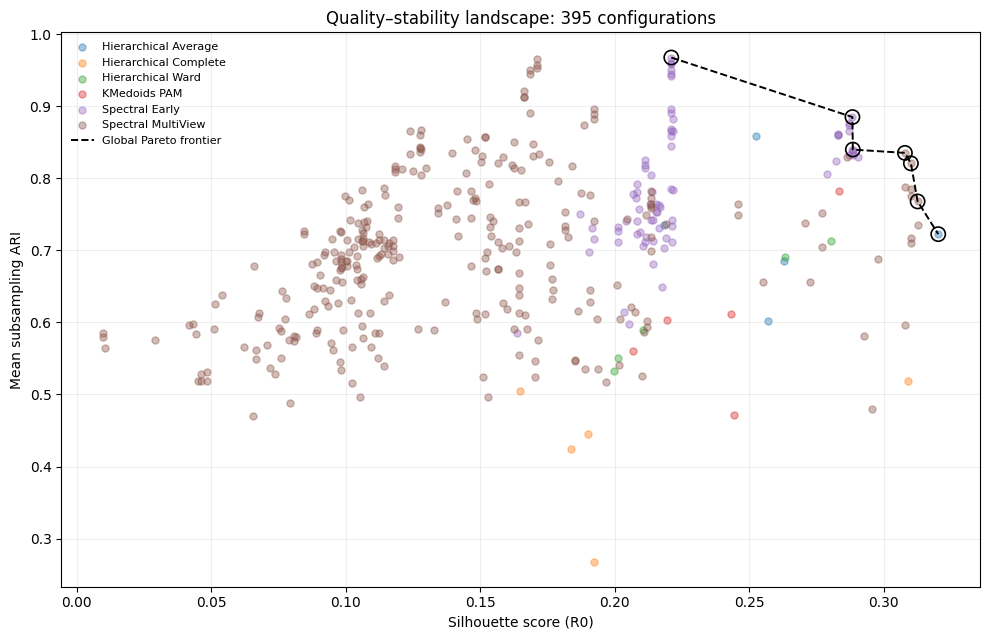


CELL 6 COMPLETED
No final model has been selected.
Outputs: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/06_stability_selection/R0_all395_selection_seed_aligned_v2


In [ ]:

# ============================================================
# CELL 6 — PARETO FRONTIER & SELECTION SENSITIVITY
# All 395 configurations; diagnostic selection only
#
# Methodological basis:
# Multi-objective / Pareto optimization
# Rousseeuw (1987): Silhouette
# von Luxburg (2010): stability limitations
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

Q_COL = "silhouette_R0"
S_COL = "mean_ARI"
TOL = 1e-12


def pareto_mask(data, q_col=Q_COL, s_col=S_COL):
    """
    Pareto non-dominated solutions:
    maximize both quality and stability.
    """

    q = data[q_col].to_numpy(dtype=float)
    s = data[s_col].to_numpy(dtype=float)

    if not (
        np.isfinite(q).all()
        and np.isfinite(s).all()
    ):
        raise ValueError(
            "Pareto criteria contain non-finite values."
        )

    keep = np.ones(len(data), dtype=bool)

    for i in range(len(data)):

        dominates_i = (
            (q >= q[i] - TOL)
            & (s >= s[i] - TOL)
            & (
                (q > q[i] + TOL)
                | (s > s[i] + TOL)
            )
        )

        dominates_i[i] = False
        keep[i] = not dominates_i.any()

    return keep


# ------------------------------------------------------------
# 1. GLOBAL PARETO FRONTIER
# ------------------------------------------------------------

analysis = S_QC.copy()

assert len(analysis) == 395
assert analysis["model_id"].is_unique

analysis["pareto_global"] = pareto_mask(
    analysis
)

# Also evaluate within-K frontiers.
analysis["pareto_within_K"] = False

for k, sub in analysis.groupby("K"):
    analysis.loc[
        sub.index, "pareto_within_K"
    ] = pareto_mask(sub)

global_frontier = (
    analysis.loc[
        analysis["pareto_global"]
    ]
    .sort_values(
        Q_COL, ascending=False
    )
)

print("A. GLOBAL PARETO FRONTIER")
print(
    "Non-dominated configurations:",
    len(global_frontier)
)

display(
    global_frontier[
        [
            "model_id", "method", "K",
            "silhouette_R0", "mean_ARI",
            "p10_ARI", "smallest_cluster",
            "worst_mean_jaccard"
        ]
    ].round(4)
)

print("\nB. NON-DOMINATED CONFIGURATIONS WITHIN EACH K")

within_k = analysis.loc[
    analysis["pareto_within_K"]
]

display(
    within_k.groupby(
        ["K", "method"]
    ).size().unstack(fill_value=0)
)

# ------------------------------------------------------------
# 2. QUALITY TOLERANCE SENSITIVITY
# ------------------------------------------------------------

Q_MAX = float(
    analysis[Q_COL].max()
)

DELTA_GRID = [
    0.00, 0.02, 0.03,
    0.05, 0.07, 0.10
]

selection_records = []

for delta in DELTA_GRID:

    threshold = Q_MAX - delta

    eligible = analysis.loc[
        analysis[Q_COL] >= threshold - TOL
    ].copy()

    assert len(eligible) >= 1

    # Stability first, followed by lower-tail stability,
    # quality and deterministic ID for exact ties.
    ranked = eligible.sort_values(
        [
            "mean_ARI",
            "p10_ARI",
            "silhouette_R0",
            "model_id"
        ],
        ascending=[False, False, False, True],
        kind="stable"
    )

    chosen = ranked.iloc[0]

    selection_records.append({
        "delta": delta,
        "quality_threshold": threshold,
        "n_eligible": len(eligible),
        "selected_model": chosen["model_id"],
        "method": chosen["method"],
        "K": int(chosen["K"]),
        "silhouette": float(
            chosen["silhouette_R0"]
        ),
        "mean_ARI": float(
            chosen["mean_ARI"]
        ),
        "p10_ARI": float(
            chosen["p10_ARI"]
        ),
        "smallest_cluster": int(
            chosen["smallest_cluster"]
        ),
        "worst_mean_jaccard": float(
            chosen["worst_mean_jaccard"]
        ),
        "lowest_observation_rate": float(
            chosen["lowest_observation_rate"]
        )
    })

selection_sensitivity = pd.DataFrame(
    selection_records
)

print("\nC. QUALITY TOLERANCE SENSITIVITY")
print("Q_max =", round(Q_MAX, 6))

display(
    selection_sensitivity.round(4)
)

# ------------------------------------------------------------
# 3. SAME FULL-DATA PARTITION,
#    POTENTIALLY DIFFERENT STABILITY
# ------------------------------------------------------------

partition_stability = analysis.merge(
    P[["model_id", "partition_id"]],
    on="model_id",
    validate="one_to_one"
)

partition_comparison = (
    partition_stability.groupby(
        "partition_id", as_index=False
    )
    .agg(
        n_configurations=(
            "model_id", "count"
        ),
        min_stability=(
            "mean_ARI", "min"
        ),
        max_stability=(
            "mean_ARI", "max"
        )
    )
)

partition_comparison["stability_range"] = (
    partition_comparison["max_stability"]
    - partition_comparison["min_stability"]
)

repeated_partitions = (
    partition_comparison.loc[
        partition_comparison["n_configurations"] > 1
    ]
    .sort_values(
        "stability_range",
        ascending=False
    )
)

print("\nD. SAME PARTITION, DIFFERENT STABILITY")
display(
    repeated_partitions.head(15).round(4)
)

# ------------------------------------------------------------
# 4. DIAGNOSTIC PLOT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6.5))

for method, sub in analysis.groupby("method"):

    ax.scatter(
        sub[Q_COL],
        sub[S_COL],
        s=26,
        alpha=0.40,
        label=method.replace("_", " ")
    )

front = global_frontier.sort_values(Q_COL)

ax.plot(
    front[Q_COL],
    front[S_COL],
    "--",
    linewidth=1.4,
    color="black",
    label="Global Pareto frontier"
)

ax.scatter(
    front[Q_COL],
    front[S_COL],
    s=105,
    facecolors="none",
    edgecolors="black",
    linewidths=1.2
)

ax.set_xlabel("Silhouette score (R0)")
ax.set_ylabel("Mean subsampling ARI")
ax.set_title(
    "Quality–stability landscape: 395 configurations"
)

ax.grid(alpha=0.2)
ax.legend(
    fontsize=8,
    loc="best",
    frameon=False
)

fig.tight_layout()

fig.savefig(
    OUT / "quality_stability_global_pareto.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUT / "quality_stability_global_pareto.svg",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. SAVE
# ------------------------------------------------------------

analysis.to_csv(
    OUT / "all395_pareto_flags.csv",
    index=False
)

global_frontier.to_csv(
    OUT / "global_pareto_frontier.csv",
    index=False
)

selection_sensitivity.to_csv(
    OUT / "quality_tolerance_sensitivity.csv",
    index=False
)

partition_comparison.to_csv(
    OUT / "identical_partition_stability_ranges.csv",
    index=False
)

print("\nCELL 6 COMPLETED")
print("No final model has been selected.")
print("Outputs:", OUT)


# Audit konsistensi hasil refitting dan random seed

In [ ]:
# ============================================================
# CELL 7 — FULL-DATA REFIT AND RANDOM-SEED AUDIT
#
# Objective:
# Check whether the stability refitting function reproduces
# the reference partitions from the original grid search.
#
# No model selection.
# ============================================================

import numpy as np
import pandas as pd
import json

from sklearn.metrics import adjusted_rand_score
from IPython.display import display

# ------------------------------------------------------------
# 1. VERIFY THE TWO MODELING SEEDS
# ------------------------------------------------------------

grid_protocol = json.loads(
    (GRID_DIR / "protocol.json").read_text(
        encoding="utf-8"
    )
)

stability_protocol = json.loads(
    (OUT / "manifest.json").read_text(
        encoding="utf-8"
    )
)

GRID_MODEL_SEED = int(
    grid_protocol["random_seed"]
)

# Di V2 manifest, kunci 'seed' dipecah menjadi 'model_seed' dan 'subsample_seed'
STABILITY_MODEL_SEED = int(
    stability_protocol["model_seed"]
)

print("Grid Search model seed:", GRID_MODEL_SEED)
print("Stability refitting seed:", STABILITY_MODEL_SEED)
print(
    "Seeds identical:",
    GRID_MODEL_SEED == STABILITY_MODEL_SEED
)

# ------------------------------------------------------------
# 2. REFIT ALL MODELS ON THE COMPLETE DATASET
# ------------------------------------------------------------

full_indices = np.arange(len(df))

ctx_audit = make_fit_context(
    full_indices
)

audit_records = []

for row in grid.to_dict("records"):

    model_id = row["model_id"]

    reference = labels_full[
        model_id
    ].to_numpy(dtype=int)

    try:
        fitted = fit_model(
            row, ctx_audit
        )

        ari = adjusted_rand_score(
            reference, fitted
        )

        same_partition = bool(
            np.isclose(ari, 1.0, atol=1e-12)
        )

        audit_records.append({
            "model_id": model_id,
            "method": row["method"],
            "K": int(row["K"]),
            "ARI_full_refit": ari,
            "same_partition": same_partition,
            "status": "SUCCESS",
            "error": ""
        })

    except Exception as exc:

        audit_records.append({
            "model_id": model_id,
            "method": row["method"],
            "K": int(row["K"]),
            "ARI_full_refit": np.nan,
            "same_partition": False,
            "status": "FAILED",
            "error": (
                f"{type(exc).__name__}: {exc}"
            )
        })


seed_audit = pd.DataFrame(
    audit_records
)

assert len(seed_audit) == 395

# ------------------------------------------------------------
# 3. METHOD-LEVEL DIAGNOSTICS
# ------------------------------------------------------------

method_audit = (
    seed_audit.groupby(
        "method", as_index=False
    )
    .agg(
        n_models=("model_id", "count"),
        n_same_partitions=(
            "same_partition", "sum"
        ),
        min_ARI=("ARI_full_refit", "min")
    )
)

method_audit["n_different_partitions"] = (
    method_audit["n_models"]
    - method_audit["n_same_partitions"]
)

print("\nA. MODEL REFIT CONSISTENCY:")
display(method_audit.round(5))

mismatches = seed_audit.loc[
    ~seed_audit["same_partition"]
]

print("\nB. NON-REPRODUCED REFERENCE PARTITIONS:")
print("Count:", len(mismatches))

if len(mismatches):
    display(
        mismatches.sort_values(
            "ARI_full_refit"
        ).head(30)
    )
else:
    print(
        "All reference partitions reproduced "
        "on complete data."
    )

# ------------------------------------------------------------
# 4. CHECK IMPORTANT PARETO CONFIGURATIONS
# ------------------------------------------------------------

pareto_ids = [
    "Hierarchical_Average_K2",
    "Multi_K2_G5_S10_food50",
    "Multi_K2_G24_S7_food50",
    "Multi_K2_G24_S10_food50",
    "Early_K3_G12_S7",
    "Early_K3_G24_S10",
    "Early_K2_G12_S10"
]

print("\nC. PARETO MODEL CONSISTENCY:")

display(
    seed_audit.loc[
        seed_audit["model_id"].isin(
            pareto_ids
        ),
        [
            "model_id",
            "ARI_full_refit",
            "same_partition",
            "status"
        ]
    ].round(6)
)

# ------------------------------------------------------------
# 5. SAVE AUDIT RESULTS
# ------------------------------------------------------------

seed_audit.to_csv(
    OUT / "full_data_refit_seed_audit.csv",
    index=False
)

method_audit.to_csv(
    OUT / "seed_audit_by_method.csv",
    index=False
)

print("\nSEED CONSISTENCY AUDIT COMPLETED")

if len(mismatches) > 0:
    print(
        "ACTION REQUIRED: Some reference partitions "
        "are not reproduced."
    )
    print(
        "Do not perform independent stability "
        "evaluation before resolving this."
    )
else:
    print(
        "Full-data label consistency passed. "
        "Separate model and resampling seeds "
        "in the finalized protocol."
    )


Grid Search model seed: 20261018
Stability refitting seed: 20261018
Seeds identical: True

A. MODEL REFIT CONSISTENCY:


,method,n_models,n_same_partitions,min_ARI,n_different_partitions
0,Hierarchical_Average,5,5,1.0,0
1,Hierarchical_Complete,5,5,1.0,0
2,Hierarchical_Ward,5,5,1.0,0
3,KMedoids_PAM,5,5,1.0,0
4,Spectral_Early,75,75,1.0,0
5,Spectral_MultiView,300,300,1.0,0



B. NON-REPRODUCED REFERENCE PARTITIONS:
Count: 0
All reference partitions reproduced on complete data.

C. PARETO MODEL CONSISTENCY:


,model_id,ARI_full_refit,same_partition,status
10,Hierarchical_Average_K2,1.0,True,SUCCESS
56,Early_K3_G12_S7,1.0,True,SUCCESS
60,Early_K2_G12_S10,1.0,True,SUCCESS
91,Early_K3_G24_S10,1.0,True,SUCCESS
180,Multi_K2_G5_S10_food50,1.0,True,SUCCESS
235,Multi_K2_G24_S7_food50,1.0,True,SUCCESS
240,Multi_K2_G24_S10_food50,1.0,True,SUCCESS



SEED CONSISTENCY AUDIT COMPLETED
Full-data label consistency passed. Separate model and resampling seeds in the finalized protocol.


# Initialization sensitivity pada kandidat Pareto

In [ ]:

# ============================================================
# CELL 8 — INITIALIZATION SENSITIVITY
#
# Fixed observations, varying model random state.
#
# 7 Pareto configurations + 2 contextual benchmarks
# 10 model seeds × (full data + 20 selection subsets)
#
# Outputs are separate from stability selection V2.
# ============================================================

from pathlib import Path
from sklearn.metrics import adjusted_rand_score
from IPython.display import display

import numpy as np
import pandas as pd
import hashlib
import json
import os

V2_DIR = (
    ROOT / "03_outputs" / "06_stability_selection"
    / "R0_all395_selection_seed_aligned_v2"
)

pareto_file = V2_DIR / "all395_pareto_flags.csv"

assert pareto_file.exists()

pareto_data = pd.read_csv(pareto_file)

pareto_ids = (
    pareto_data.loc[
        pareto_data["pareto_global"]
        .astype(str).str.lower().eq("true"),
        "model_id"
    ]
    .tolist()
)

assert len(pareto_ids) == 7

BENCHMARK_IDS = [
    "KMedoids_PAM_K3",
    "Multi_K3_G12_S10_climate50"
]

MODEL_IDS = list(dict.fromkeys(
    pareto_ids + BENCHMARK_IDS
))

assert len(MODEL_IDS) == 9
assert set(MODEL_IDS).issubset(set(grid["model_id"]))

MODEL_SEEDS = list(range(20261018, 20261028))

# Reuse 20 of the 100 existing selection subsets.
# Not an independent resampling sample.
SUBSET_POSITIONS = list(range(0, 100, 5))

assert len(SUBSETS) == 100
assert len(SUBSET_POSITIONS) == 20

SAMPLE_PLAN = [
    ("full", np.arange(len(df), dtype=int))
] + [
    (f"selection_{i+1:03d}", SUBSETS[i].copy())
    for i in SUBSET_POSITIONS
]

MODEL_ROWS = (
    grid.set_index("model_id")
    .loc[MODEL_IDS]
    .reset_index()
    .to_dict("records")
)

SEED_OUT = (
    ROOT / "03_outputs"
    / "07_initialization_sensitivity"
    / "R0_pareto9_10seeds_20subsets_v1"
)

SEED_OUT.mkdir(parents=True, exist_ok=True)

BATCH_DIR = SEED_OUT / "batches"
BATCH_DIR.mkdir(exist_ok=True)

manifest = {
    "stage": "Initialization sensitivity",
    "source": "R0 stability selection V2",
    "model_ids": MODEL_IDS,
    "model_seeds": MODEL_SEEDS,
    "subset_positions_zero_based": SUBSET_POSITIONS,
    "sample_fraction": 0.8,
    "subsample_source_seed": 20261019,
    "fixed_subsets_across_model_seeds": True,
    "n_models": len(MODEL_IDS),
    "n_seeds": len(MODEL_SEEDS),
    "n_sample_sets": len(SAMPLE_PLAN),
    "status": "DIAGNOSTIC_NOT_INDEPENDENT_VALIDATION"
}

manifest_path = SEED_OUT / "manifest.json"

if manifest_path.exists():
    previous = json.loads(
        manifest_path.read_text(encoding="utf-8")
    )
    if previous != manifest:
        raise RuntimeError("Existing manifest mismatch.")
else:
    manifest_path.write_text(
        json.dumps(manifest, indent=2),
        encoding="utf-8"
    )

expected_per_sample = len(MODEL_IDS) * len(MODEL_SEEDS)

original_seed = SEED

try:
    for sample_id, indices in SAMPLE_PLAN:

        target = BATCH_DIR / f"{sample_id}.csv"

        if target.exists():
            saved = pd.read_csv(target)

            if (
                len(saved) != expected_per_sample
                or saved.duplicated(
                    ["model_id", "model_seed"]
                ).any()
                or not saved["status"].eq("SUCCESS").all()
            ):
                raise RuntimeError(
                    f"Incomplete/invalid checkpoint: {target}"
                )

            print("Verified checkpoint:", sample_id)
            continue

        # Identical data preprocessing and graphs
        # for all model seeds within this sample.
        ctx = make_fit_context(indices)

        records = []

        for row in MODEL_ROWS:
            for model_seed in MODEL_SEEDS:

                # fit_model reads the global SEED variable.
                SEED = int(model_seed)

                try:
                    fitted = fit_model(row, ctx)

                    records.append({
                        "sample_id": sample_id,
                        "model_id": row["model_id"],
                        "model_seed": model_seed,
                        "n": len(indices),
                        "status": "SUCCESS",
                        "labels_json": json.dumps(
                            fitted.astype(int).tolist()
                        ),
                        "error": ""
                    })

                except Exception as exc:
                    records.append({
                        "sample_id": sample_id,
                        "model_id": row["model_id"],
                        "model_seed": model_seed,
                        "n": len(indices),
                        "status": "FAILED",
                        "labels_json": "",
                        "error": (
                            f"{type(exc).__name__}: {exc}"
                        )
                    })

        batch = pd.DataFrame(records)

        assert len(batch) == expected_per_sample
        assert not batch.duplicated(
            ["sample_id", "model_id", "model_seed"]
        ).any()

        tmp = target.with_suffix(".tmp")
        batch.to_csv(tmp, index=False)
        os.replace(tmp, target)

        print(
            f"Saved {sample_id}: "
            f"{batch['status'].eq('SUCCESS').sum()}"
            f"/{expected_per_sample} successful fits"
        )

finally:
    SEED = original_seed

print("\nINITIALIZATION FITTING COMPLETED")
print("Models:", len(MODEL_IDS))
print("Seeds:", len(MODEL_SEEDS))
print("Sample sets:", len(SAMPLE_PLAN))
print(
    "Expected model fits:",
    len(MODEL_IDS) * len(MODEL_SEEDS) * len(SAMPLE_PLAN)
)
print("Output:", SEED_OUT)


Saved full: 90/90 successful fits
Saved selection_001: 90/90 successful fits
Saved selection_006: 90/90 successful fits
Saved selection_011: 90/90 successful fits
Saved selection_016: 90/90 successful fits
Saved selection_021: 90/90 successful fits
Saved selection_026: 90/90 successful fits
Saved selection_031: 90/90 successful fits
Saved selection_036: 90/90 successful fits
Saved selection_041: 90/90 successful fits
Saved selection_046: 90/90 successful fits
Saved selection_051: 90/90 successful fits
Saved selection_056: 90/90 successful fits
Saved selection_061: 90/90 successful fits
Saved selection_066: 90/90 successful fits
Saved selection_071: 90/90 successful fits
Saved selection_076: 90/90 successful fits
Saved selection_081: 90/90 successful fits
Saved selection_086: 90/90 successful fits
Saved selection_091: 90/90 successful fits
Saved selection_096: 90/90 successful fits

INITIALIZATION FITTING COMPLETED
Models: 9
Seeds: 10
Sample sets: 21
Expected model fits: 1890
Output: /c

# Mengukur pengaruh random initialization

In [ ]:

# ============================================================
# CELL 9 — INITIALIZATION SENSITIVITY SUMMARY
#
# Pairwise ARI across model seeds with identical data.
# No clustering refitting.
# ============================================================

from itertools import combinations

files = sorted(BATCH_DIR.glob("*.csv"))

assert len(files) == 21

seed_results = pd.concat(
    [pd.read_csv(path) for path in files],
    ignore_index=True
)

expected = len(MODEL_IDS) * len(MODEL_SEEDS) * 21

assert len(seed_results) == expected
assert not seed_results.duplicated(
    ["sample_id", "model_id", "model_seed"]
).any()

failures = seed_results.loc[
    seed_results["status"] != "SUCCESS"
]

print("A. COMPUTATIONAL COVERAGE")
print("Expected fits:", expected)
print("Successful:",
      int(seed_results["status"].eq("SUCCESS").sum()))
print("Failed:", len(failures))

if not failures.empty:
    display(failures)
    raise RuntimeError(
        "Resolve failed fits before interpreting results."
    )

pairwise_records = []
sample_summaries = []

for (sample_id, model_id), sub in seed_results.groupby(
    ["sample_id", "model_id"],
    sort=True
):

    sub = sub.sort_values("model_seed")

    assert len(sub) == len(MODEL_SEEDS)

    partitions = {
        int(r.model_seed): np.array(
            json.loads(r.labels_json),
            dtype=int
        )
        for r in sub.itertuples(index=False)
    }

    pair_ari = []

    for seed_a, seed_b in combinations(
        MODEL_SEEDS, 2
    ):
        ari = adjusted_rand_score(
            partitions[seed_a],
            partitions[seed_b]
        )

        pair_ari.append(ari)

        pairwise_records.append({
            "sample_id": sample_id,
            "model_id": model_id,
            "seed_a": seed_a,
            "seed_b": seed_b,
            "ARI": float(ari)
        })

    pair_ari = np.array(pair_ari)

    sample_summaries.append({
        "sample_id": sample_id,
        "model_id": model_id,
        "n_seed_pairs": len(pair_ari),
        "mean_pairwise_ARI": float(pair_ari.mean()),
        "p10_pairwise_ARI": float(
            np.quantile(pair_ari, 0.10)
        ),
        "minimum_pairwise_ARI": float(
            pair_ari.min()
        ),
        "fraction_identical_pairs": float(
            np.isclose(
                pair_ari, 1.0,
                rtol=0, atol=1e-12
            ).mean()
        )
    })

pairwise = pd.DataFrame(pairwise_records)
sample_stats = pd.DataFrame(sample_summaries)

# Full-data sensitivity
full_summary = (
    sample_stats.loc[
        sample_stats["sample_id"] == "full"
    ]
    .drop(columns=["sample_id"])
    .sort_values(
        "mean_pairwise_ARI", ascending=False
    )
)

# Subsampling sensitivity.
# Aggregate per-subset summaries; not 900 independent pairs.
subset_stats = sample_stats.loc[
    sample_stats["sample_id"] != "full"
].copy()

subset_summary = (
    subset_stats.groupby("model_id", as_index=False)
    .agg(
        n_subsets=("sample_id", "nunique"),
        mean_seed_ARI=(
            "mean_pairwise_ARI", "mean"
        ),
        median_seed_ARI=(
            "mean_pairwise_ARI", "median"
        ),
        worst_subset_seed_ARI=(
            "mean_pairwise_ARI", "min"
        ),
        mean_fraction_identical=(
            "fraction_identical_pairs", "mean"
        ),
        worst_pairwise_ARI=(
            "minimum_pairwise_ARI", "min"
        )
    )
    .sort_values(
        "mean_seed_ARI", ascending=False
    )
)

print("\nB. FULL-DATA INITIALIZATION SENSITIVITY")
display(full_summary.round(4))

print("\nC. SUBSAMPLE INITIALIZATION SENSITIVITY")
display(subset_summary.round(4))

# Compare both diagnostics without blending scores.
comparison = (
    subset_summary.merge(
        full_summary[[
            "model_id",
            "mean_pairwise_ARI",
            "fraction_identical_pairs"
        ]].rename(columns={
            "mean_pairwise_ARI": "full_seed_ARI",
            "fraction_identical_pairs": (
                "full_fraction_identical"
            )
        }),
        on="model_id",
        validate="one_to_one"
    )
)

print("\nD. FULL DATA VS SUBSAMPLING")
display(comparison.round(4))

# Reproducibility outputs
pairwise.to_csv(
    SEED_OUT / "seed_pairwise_ARI.csv",
    index=False
)

sample_stats.to_csv(
    SEED_OUT / "seed_sensitivity_by_sample.csv",
    index=False
)

full_summary.to_csv(
    SEED_OUT / "full_data_seed_sensitivity.csv",
    index=False
)

subset_summary.to_csv(
    SEED_OUT / "subsample_seed_sensitivity.csv",
    index=False
)

comparison.to_csv(
    SEED_OUT / "seed_sensitivity_comparison.csv",
    index=False
)

print("\nINITIALIZATION SENSITIVITY AUDIT COMPLETED")
print("Saved:", SEED_OUT)


A. COMPUTATIONAL COVERAGE
Expected fits: 1890
Successful: 1890
Failed: 0

B. FULL-DATA INITIALIZATION SENSITIVITY


,model_id,n_seed_pairs,mean_pairwise_ARI,p10_pairwise_ARI,minimum_pairwise_ARI,fraction_identical_pairs
0,Early_K2_G12_S10,45,1.0,1.0,1.0,1.0
1,Early_K3_G12_S7,45,1.0,1.0,1.0,1.0
2,Early_K3_G24_S10,45,1.0,1.0,1.0,1.0
3,Hierarchical_Average_K2,45,1.0,1.0,1.0,1.0
4,KMedoids_PAM_K3,45,1.0,1.0,1.0,1.0
5,Multi_K2_G24_S10_food50,45,1.0,1.0,1.0,1.0
6,Multi_K2_G24_S7_food50,45,1.0,1.0,1.0,1.0
7,Multi_K2_G5_S10_food50,45,1.0,1.0,1.0,1.0
8,Multi_K3_G12_S10_climate50,45,1.0,1.0,1.0,1.0



C. SUBSAMPLE INITIALIZATION SENSITIVITY


,model_id,n_subsets,mean_seed_ARI,median_seed_ARI,worst_subset_seed_ARI,mean_fraction_identical,worst_pairwise_ARI
4,KMedoids_PAM_K3,20,1.0000,1.0,1.0000,1.0000,1.0000
8,Multi_K3_G12_S10_climate50,20,1.0000,1.0,1.0000,1.0000,1.0000
3,Hierarchical_Average_K2,20,1.0000,1.0,1.0000,1.0000,1.0000
1,Early_K3_G12_S7,20,0.9990,1.0,0.9791,0.9767,0.9553
0,Early_K2_G12_S10,20,0.9984,1.0,0.9683,0.9733,0.9406
7,Multi_K2_G5_S10_food50,20,0.9978,1.0,0.9569,0.9678,0.8839
2,Early_K3_G24_S10,20,0.9964,1.0,0.9540,0.9500,0.9014
6,Multi_K2_G24_S7_food50,20,0.9936,1.0,0.9381,0.9278,0.8820
5,Multi_K2_G24_S10_food50,20,0.9921,1.0,0.9061,0.9200,0.8239



D. FULL DATA VS SUBSAMPLING


,model_id,n_subsets,mean_seed_ARI,median_seed_ARI,worst_subset_seed_ARI,mean_fraction_identical,worst_pairwise_ARI,full_seed_ARI,full_fraction_identical
0,KMedoids_PAM_K3,20,1.0000,1.0,1.0000,1.0000,1.0000,1.0,1.0
1,Multi_K3_G12_S10_climate50,20,1.0000,1.0,1.0000,1.0000,1.0000,1.0,1.0
2,Hierarchical_Average_K2,20,1.0000,1.0,1.0000,1.0000,1.0000,1.0,1.0
3,Early_K3_G12_S7,20,0.9990,1.0,0.9791,0.9767,0.9553,1.0,1.0
4,Early_K2_G12_S10,20,0.9984,1.0,0.9683,0.9733,0.9406,1.0,1.0
5,Multi_K2_G5_S10_food50,20,0.9978,1.0,0.9569,0.9678,0.8839,1.0,1.0
6,Early_K3_G24_S10,20,0.9964,1.0,0.9540,0.9500,0.9014,1.0,1.0
7,Multi_K2_G24_S7_food50,20,0.9936,1.0,0.9381,0.9278,0.8820,1.0,1.0
8,Multi_K2_G24_S10_food50,20,0.9921,1.0,0.9061,0.9200,0.8239,1.0,1.0



INITIALIZATION SENSITIVITY AUDIT COMPLETED
Saved: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/07_initialization_sensitivity/R0_pareto9_10seeds_20subsets_v1


#